# Monetary Relief Prediction

This notebook covers the proposal's secondary task: given a complaint, predict whether the company will close it
**with monetary relief** (a refund, reimbursement, or other payment to the consumer). This is a rare binary outcome
(about 5% of closed complaints), so the evaluation focuses on **ROC-AUC** and **PR-AUC** (average precision),
with PR-AUC compared against the positive-class prevalence.

Label definition (from `01_data_cleaning.ipynb`): `monetary_relief = 1` for "Closed with monetary relief",
`0` for every other closed outcome, and missing for "Untimely response" / "In progress" complaints, which have no
final outcome yet and are excluded here. The `split` column from the cleaning notebook is reused, so the test set
matches every other notebook in the project.

Variants compared:

| | Variant | Features | Model |
|---|---|---|---|
| (a) | Prevalence baseline | none (class prior) | `DummyClassifier` |
| (b) | Product only | one-hot Product | Logistic Regression |
| (c) | Text only | TF-IDF of `clean_narrative` | Logistic Regression |
| (d) | Text + product | (c) + (b) | Logistic Regression |
| (e) | Text + product + company | (d) + one-hot of the 50 most frequent companies | Logistic Regression |
| (f) | Linear SVM | same as (e) | `LinearSVC` |

In [1]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC

In [2]:
RANDOM_STATE = 42
N_JOBS = 3   # 3 folds (and 3 x 3 grid fits) divide evenly over 3 workers; keeps RAM use modest

DATA_PATH = Path("../../data/processed/complaint_router_modeling_data.csv")
FIG_DIR = Path("../../figures")
METRICS_DIR = Path("../../results/metrics")
MODEL_DIR = Path("../../models")

for folder in (FIG_DIR, METRICS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

# Shared TF-IDF configuration used by every notebook in the project
TFIDF_PARAMS = dict(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000,
)

C_GRID = [0.1, 0.5, 2]          # Logistic Regression
SVM_C_GRID = [0.02, 0.1, 0.5]   # LinearSVC needs stronger regularization than LR on the same features
TOP_N_COMPANIES = 50

# One fixed color per variant, in the same order on every plot
VARIANT_ORDER = ["product", "text", "text_product", "text_product_company", "linear_svm"]
VARIANT_COLORS = {
    "product": "#2a78d6",
    "text": "#eb6834",
    "text_product": "#1baf7a",
    "text_product_company": "#eda100",
    "linear_svm": "#e87ba4",
}
BASELINE_COLOR = "#8c8c8c"

## 1. Load Data

Only the columns needed for this task are loaded (the raw narrative column is skipped to save memory).

In [3]:
use_cols = [
    "Product",
    "Company",
    "Company response to consumer",
    "clean_narrative",
    "monetary_relief",
    "split",
]

df = pd.read_csv(DATA_PATH, usecols=use_cols)

print("Dataset shape:", df.shape)
print(df["Company response to consumer"].value_counts())

Dataset shape: (162500, 6)
Company response to consumer
Closed with explanation            125907
Closed with non-monetary relief     25480
Closed with monetary relief          9206
Untimely response                    1880
In progress                            27
Name: count, dtype: int64


### Keep Complaints With a Final Outcome

Complaints without a final outcome (untimely response or still in progress) have a missing label and are dropped.

In [4]:
excluded = df[df["monetary_relief"].isna()]
print(f"Excluded (no final outcome): {len(excluded):,}")
print(excluded["Company response to consumer"].value_counts().to_string())

relief = df[df["monetary_relief"].notna()].copy()
relief["monetary_relief"] = relief["monetary_relief"].astype(int)
assert relief["clean_narrative"].notna().all()

train_rel = relief[relief["split"] == "train"].reset_index(drop=True)
test_rel = relief[relief["split"] == "test"].reset_index(drop=True)

y_train = train_rel["monetary_relief"].to_numpy()
y_test = test_rel["monetary_relief"].to_numpy()

print(f"\nLabeled complaints: {len(relief):,}")
print(f"Training samples: {len(train_rel):,}")
print(f"Testing samples: {len(test_rel):,}")

Excluded (no final outcome): 1,907
Company response to consumer
Untimely response    1880
In progress            27

Labeled complaints: 160,593
Training samples: 128,491
Testing samples: 32,102


## 2. Prevalence of Monetary Relief

In [5]:
prevalence_overall = relief["monetary_relief"].mean()
prevalence_train = y_train.mean()
prevalence_test = y_test.mean()

print(f"Monetary relief prevalence (overall): {prevalence_overall:.4f}")
print(f"Monetary relief prevalence (train):   {prevalence_train:.4f}")
print(f"Monetary relief prevalence (test):    {prevalence_test:.4f}")
print(f"Positive test complaints: {y_test.sum():,} of {len(y_test):,}")

Monetary relief prevalence (overall): 0.0573
Monetary relief prevalence (train):   0.0576
Monetary relief prevalence (test):    0.0564
Positive test complaints: 1,810 of 32,102


In [6]:
by_product = relief.groupby("Product")["monetary_relief"].agg(
    complaints="size",
    monetary_relief="sum",
    rate="mean",
)
by_product["train_rate"] = train_rel.groupby("Product")["monetary_relief"].mean()
by_product["test_rate"] = test_rel.groupby("Product")["monetary_relief"].mean()
by_product.index = by_product.index.map(SHORT_LABELS)

by_product.sort_values("rate", ascending=False).round(4)

,complaints,monetary_relief,rate,train_rate,test_rate
Product,,,,,
Prepaid Card,4994,1005,0.2012,0.2008,0.2032
Credit Card,19982,3647,0.1825,0.1853,0.1712
Checking/Savings,19981,2615,0.1309,0.1313,0.1290
Money Transfer,14961,777,0.0519,0.0514,0.0541
Debt/Credit Mgmt,4807,187,0.0389,0.0404,0.0331
Payday/Personal Loan,7410,284,0.0383,0.0378,0.0404
Vehicle Loan,9939,274,0.0276,0.0275,0.0277
Mortgage,9946,196,0.0197,0.0187,0.0236
Student Loan,8854,59,0.0067,0.0066,0.0069


Monetary relief is rare: **5.73%** of the 160,593 labeled complaints (5.76% in train, 5.64% in test; 1,810 positive
test complaints). The rate depends heavily on the product. About one in five **Prepaid Card (20.1%)** and
**Credit Card (18.3%)** complaints end with monetary relief, and Checking/Savings follows at 13.1%. At the other end
are **Debt Collection (0.40%)** and **Credit Reporting (0.18%)**: Credit Reporting is the largest product
(34,952 complaints) but has only 63 positives. Train and test rates agree closely for every product, so the
product alone already carries a lot of signal. Because positives are so rare, accuracy is meaningless here
(predicting "no relief" for everyone is about 94% accurate), which is why every variant is compared on ROC-AUC
and PR-AUC.

## 3. Label Noise and Company Effects (Training Data Only)

### Template Letters

Many consumers submit near-identical template letters (for example, credit-dispute templates sent to several
companies). Complaints whose cleaned text shares the same first 200 characters are grouped below. Groups where some
copies received monetary relief and others did not show that the outcome is not determined by the text alone.

In [7]:
PREFIX_CHARS = 200

templates = (
    train_rel.assign(prefix=train_rel["clean_narrative"].str[:PREFIX_CHARS])
    .groupby("prefix")
    .agg(
        complaints=("monetary_relief", "size"),
        companies=("Company", "nunique"),
        relief_rate=("monetary_relief", "mean"),
    )
)
templates = templates[templates["complaints"] >= 2]
mixed = templates[(templates["relief_rate"] > 0) & (templates["relief_rate"] < 1)]

n_template_complaints = templates["complaints"].sum()
print(f"Train complaints sharing their first {PREFIX_CHARS} characters with another complaint: "
      f"{n_template_complaints:,} ({n_template_complaints / len(train_rel):.1%})")
print(f"Template groups: {len(templates):,} (sent to 2+ companies: {(templates['companies'] >= 2).sum():,})")
print(f"Groups with BOTH outcomes: {len(mixed):,} groups, {mixed['complaints'].sum():,} complaints")
print(f"Monetary relief rate inside template groups: "
      f"{(templates['relief_rate'] * templates['complaints']).sum() / n_template_complaints:.4f}")

largest = templates.sort_values("complaints", ascending=False).head(8).reset_index()
largest["prefix"] = largest["prefix"].str[:90] + "..."
largest.round(3)

Train complaints sharing their first 200 characters with another complaint: 7,433 (5.8%)
Template groups: 1,670 (sent to 2+ companies: 1,060)
Groups with BOTH outcomes: 7 groups, 15 complaints
Monetary relief rate inside template groups: 0.0020


,prefix,complaints,companies,relief_rate
0,i am filing a complaint against cash app ( blo...,427,1,0.0
1,i am writing to formally express my concerns r...,151,1,0.0
2,i am writing to formally express my concerns r...,107,1,0.0
3,in accordance with the fair credit reporting a...,103,3,0.0
4,i am writing to file a complaint against navy ...,76,1,0.0
5,this cfpb complaint has been filed to request ...,74,2,0.0
6,this cfpb complaint has been filed to request ...,62,1,0.0
7,this cfpb complaint has been filed to request ...,61,3,0.0


**Template-letter findings.** 7,433 training complaints (5.8%) share their first 200 characters with at least one
other complaint, forming 1,670 groups (1,060 of them sent to two or more companies). The expected label noise did
not show up: only **7 groups (15 complaints)** contain both outcomes, and the monetary relief rate inside template
groups is **0.2%**, against 5.8% overall.
- **Largest group:** the January 2025 Cash App campaign, 427 complaints against Block, Inc. with the same opening.
  The EDA found about 2,300 near-identical Cash App / Zelle narratives in total; many differ within the first
  200 characters.
- **Other large groups:** formal "I am writing to formally express my concerns" letters, Fair Credit Reporting
  Act dispute letters, and "this CFPB complaint has been filed to request..." templates. None of them received
  monetary relief.

Template letters are therefore mostly **easy negatives**, not noisy labels. Copies of the same template can land in
both train and test, which makes the task look slightly easier than it would be on new kinds of complaints.

### Relief Rate by Company

The company that receives the complaint decides the outcome, and company policies differ widely. The most frequent
companies are shown with their most common product, which illustrates how company and product are entangled.

In [8]:
top_15 = train_rel["Company"].value_counts().head(15).index

company_rates = (
    train_rel[train_rel["Company"].isin(top_15)]
    .groupby("Company")
    .agg(
        complaints=("monetary_relief", "size"),
        relief_rate=("monetary_relief", "mean"),
        main_product=("Product", lambda s: SHORT_LABELS[s.mode().iloc[0]]),
    )
    .sort_values("complaints", ascending=False)
)

company_rates.round(4)

,complaints,relief_rate,main_product
Company,,,
Experian Information Solutions Inc.,9081,0.0013,Credit Reporting
"EQUIFAX, INC.",8751,0.0000,Credit Reporting
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",8641,0.0001,Credit Reporting
"Block, Inc.",5340,0.0026,Money Transfer
CAPITAL ONE FINANCIAL CORPORATION,4375,0.0768,Credit Card
JPMORGAN CHASE & CO.,4244,0.0820,Checking/Savings
WELLS FARGO & COMPANY,3700,0.1062,Checking/Savings
"BANK OF AMERICA, NATIONAL ASSOCIATION",3595,0.3157,Checking/Savings
"CITIBANK, N.A.",3171,0.2507,Credit Card


## 4. Feature Construction

All encoders are fit on the training rows only.

- **Text:** shared TF-IDF configuration (1–2 grams, 100k features).
- **Product:** one-hot encoding of the 11 products.
- **Company:** one-hot encoding of the 50 most frequent companies in the training data; every other company is
  mapped to `"Other"`. The company is known as soon as a complaint is filed (it is the routing destination), so it is
  a legitimate input for this task.

In [9]:
start = time.perf_counter()

tfidf = TfidfVectorizer(**TFIDF_PARAMS)
X_text_train = tfidf.fit_transform(train_rel["clean_narrative"])
X_text_test = tfidf.transform(test_rel["clean_narrative"])

print(f"TF-IDF fitted in {time.perf_counter() - start:.1f} s")
print("Training TF-IDF shape:", X_text_train.shape)
print("Testing TF-IDF shape:", X_text_test.shape)

# The training text is no longer needed (test text is kept for the saved-model check)
train_rel = train_rel.drop(columns="clean_narrative")

TF-IDF fitted in 51.4 s
Training TF-IDF shape: (128491, 100000)
Testing TF-IDF shape: (32102, 100000)


In [10]:
product_encoder = OneHotEncoder(handle_unknown="ignore")
X_product_train = product_encoder.fit_transform(train_rel[["Product"]])
X_product_test = product_encoder.transform(test_rel[["Product"]])

top_companies = train_rel["Company"].value_counts().head(TOP_N_COMPANIES).index


def group_company(companies):
    return companies.where(companies.isin(top_companies), "Other").to_frame()


company_encoder = OneHotEncoder(handle_unknown="ignore")
X_company_train = company_encoder.fit_transform(group_company(train_rel["Company"]))
X_company_test = company_encoder.transform(group_company(test_rel["Company"]))

print(f"Train complaints covered by the top {TOP_N_COMPANIES} companies: "
      f"{train_rel['Company'].isin(top_companies).mean():.1%}")
print(f"Test complaints covered by the top {TOP_N_COMPANIES} companies: "
      f"{test_rel['Company'].isin(top_companies).mean():.1%}")

print("Product features:", X_product_train.shape[1])
print("Company features:", X_company_train.shape[1])

# The combined matrices are built right before the variants that use them (and freed afterwards) to save memory:
# text + product = hstack([X_text, X_product]); text + product + company = hstack([X_text, X_product, X_company])

Train complaints covered by the top 50 companies: 72.2%
Test complaints covered by the top 50 companies: 72.5%
Product features: 11
Company features: 51


## 5. Evaluation Protocol

For each variant:

1. **Tune C** with `GridSearchCV` on the training data (stratified 3-fold CV, scoring = average precision).
   The TF-IDF vocabulary is fit once on the full training set before CV; the resulting IDF leak into the
   validation folds is negligible.
2. **Choose a decision threshold** without touching the test set: `cross_val_predict` (same 3 folds, best
   parameters) gives an out-of-fold score for every training complaint, and the threshold that maximizes F1 on
   those out-of-fold scores is kept.
3. **Evaluate once on test:** ROC-AUC and PR-AUC from the continuous scores, plus precision / recall / F1 when the
   train-chosen threshold is applied to the test scores.

Logistic Regression is scored with `predict_proba`, the linear SVM with `decision_function`. Each variant's
metrics are written to `results/metrics/relief_<variant>.json`; `train_seconds` there is the time of the final
fit on the full training set only (not the CV search or the threshold step).

In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

results = {}
test_scores = {}


def positive_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def f1_optimal_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    precision, recall = precision[:-1], recall[:-1]
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0,
    )
    best = int(np.argmax(f1))
    return float(thresholds[best]), float(f1[best])


def record_result(key, display_name, features, best_params, cv_pr_auc, train_seconds,
                  threshold, oof_f1, scores, score_type):
    y_pred = (scores >= threshold).astype(int)

    metrics = {
        "model": f"relief_{key}",
        "display_name": display_name,
        "task": "relief",
        "features": features,
        "best_params": {name: float(value) for name, value in best_params.items()},
        "cv_pr_auc": float(cv_pr_auc),
        "score_type": score_type,
        "test_roc_auc": float(roc_auc_score(y_test, scores)),
        "test_pr_auc": float(average_precision_score(y_test, scores)),
        "prevalence": float(prevalence_test),
        "train_prevalence": float(prevalence_train),
        "threshold": float(threshold),
        "oof_f1": float(oof_f1),
        "test_precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "test_recall": float(recall_score(y_test, y_pred)),
        "test_f1": float(f1_score(y_test, y_pred)),
        "test_flagged_rate": float(y_pred.mean()),
        "train_seconds": round(float(train_seconds), 2),
        "n_train": int(len(y_train)),
        "n_test": int(len(y_test)),
    }

    with open(METRICS_DIR / f"relief_{key}.json", "w") as f:
        json.dump(metrics, f, indent=2)

    results[key] = metrics
    test_scores[key] = scores

    print(display_name)
    print(f"  CV PR-AUC: {metrics['cv_pr_auc']:.4f}")
    print(f"  Test ROC-AUC: {metrics['test_roc_auc']:.4f}")
    print(f"  Test PR-AUC: {metrics['test_pr_auc']:.4f} (prevalence {prevalence_test:.4f}, "
          f"lift {metrics['test_pr_auc'] / prevalence_test:.2f}x)")
    print(f"  Threshold (train OOF, F1 = {oof_f1:.4f}): {threshold:.4f}")
    print(f"  Test precision {metrics['test_precision']:.4f} | recall {metrics['test_recall']:.4f} | "
          f"F1 {metrics['test_f1']:.4f} | flagged {metrics['test_flagged_rate']:.1%}")
    return metrics


def run_variant(key, display_name, features, estimator, param_grid, X_tr, X_te):
    search = GridSearchCV(
        estimator,
        param_grid,
        scoring="average_precision",
        cv=cv,
        n_jobs=N_JOBS,
    )

    start = time.perf_counter()
    search.fit(X_tr, y_train)
    search_seconds = time.perf_counter() - start
    train_seconds = search.refit_time_   # final fit on the full training set only

    cv_table = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
    print(cv_table.round(4).to_string(index=False))
    print("Best params:", search.best_params_,
          f"| CV search + refit: {search_seconds:.1f} s | final refit: {train_seconds:.1f} s\n")

    model = search.best_estimator_
    method = "predict_proba" if hasattr(model, "predict_proba") else "decision_function"
    oof = cross_val_predict(clone(model), X_tr, y_train, cv=cv, method=method, n_jobs=N_JOBS)
    if oof.ndim == 2:
        oof = oof[:, 1]
    threshold, oof_f1 = f1_optimal_threshold(y_train, oof)

    scores = positive_scores(model, X_te)
    record_result(
        key, display_name, features, search.best_params_, search.best_score_, train_seconds,
        threshold, oof_f1, scores,
        "probability" if method == "predict_proba" else "decision_function",
    )
    return model

### (a) Prevalence Baseline

`DummyClassifier(strategy="prior")` gives every complaint the same score (the training prevalence). Its ROC-AUC is
0.5 and its PR-AUC equals the test prevalence. With a constant score, the F1-optimal threshold rule reduces to
flagging every complaint as monetary relief (recall = 1, precision = prevalence).

In [12]:
start = time.perf_counter()
dummy = DummyClassifier(strategy="prior").fit(X_product_train, y_train)
dummy_seconds = time.perf_counter() - start

dummy_cv_ap = cross_val_score(
    DummyClassifier(strategy="prior"), X_product_train, y_train, cv=cv, scoring="average_precision"
).mean()

dummy_scores = dummy.predict_proba(X_product_test)[:, 1]
dummy_threshold = float(dummy_scores.min())   # constant score: flag everything

_ = record_result(
    "prevalence",
    "Prevalence baseline (Dummy)",
    "none (class prior)",
    {},
    dummy_cv_ap,
    dummy_seconds,
    dummy_threshold,
    2 * prevalence_train / (1 + prevalence_train),
    dummy_scores,
    "probability",
)

Prevalence baseline (Dummy)
  CV PR-AUC: 0.0576
  Test ROC-AUC: 0.5000
  Test PR-AUC: 0.0564 (prevalence 0.0564, lift 1.00x)
  Threshold (train OOF, F1 = 0.1089): 0.0576
  Test precision 0.0564 | recall 1.0000 | F1 0.1067 | flagged 100.0%


### (b) Product Only

Logistic Regression on the one-hot product. With only 11 binary features this model can only learn one score per
product, so it measures how much of the task is explained by product-level relief rates.

In [13]:
product_model = run_variant(
    "product",
    "LogReg - Product only",
    "One-hot Product (11)",
    LogisticRegression(class_weight="balanced", max_iter=2000),
    {"C": C_GRID},
    X_product_train,
    X_product_test,
)

    params  mean_test_score  std_test_score
{'C': 0.1}            0.168           0.005
{'C': 0.5}            0.168           0.005
  {'C': 2}            0.168           0.005
Best params: {'C': 0.1} | CV search + refit: 6.6 s | final refit: 0.1 s

LogReg - Product only
  CV PR-AUC: 0.1680
  Test ROC-AUC: 0.8190
  Test PR-AUC: 0.1597 (prevalence 0.0564, lift 2.83x)
  Threshold (train OOF, F1 = 0.2750): 0.7839
  Test precision 0.1776 | recall 0.4901 | F1 0.2607 | flagged 15.6%


### (c) Text Only

Logistic Regression on the TF-IDF narrative features. This is the model saved for the demo, because a demo user
only types a narrative.

In [14]:
text_model = run_variant(
    "text",
    "LogReg - Text",
    "TF-IDF 1-2 grams (100k)",
    LogisticRegression(class_weight="balanced", max_iter=2000),
    {"C": C_GRID},
    X_text_train,
    X_text_test,
)

    params  mean_test_score  std_test_score
{'C': 0.1}           0.3585          0.0083
{'C': 0.5}           0.3747          0.0095
  {'C': 2}           0.3722          0.0088
Best params: {'C': 0.5} | CV search + refit: 10.7 s | final refit: 2.4 s



LogReg - Text
  CV PR-AUC: 0.3747
  Test ROC-AUC: 0.9022
  Test PR-AUC: 0.3572 (prevalence 0.0564, lift 6.34x)
  Threshold (train OOF, F1 = 0.4240): 0.7329
  Test precision 0.3398 | recall 0.5127 | F1 0.4087 | flagged 8.5%


### (d) Text + Product

In [15]:
X_tp_train = sparse.hstack([X_text_train, X_product_train], format="csr")
X_tp_test = sparse.hstack([X_text_test, X_product_test], format="csr")
print("Text + product shape:", X_tp_train.shape)

text_product_model = run_variant(
    "text_product",
    "LogReg - Text + Product",
    "TF-IDF 1-2 grams (100k) + one-hot Product",
    LogisticRegression(class_weight="balanced", max_iter=2000),
    {"C": C_GRID},
    X_tp_train,
    X_tp_test,
)

del X_tp_train, X_tp_test

Text + product shape: (128491, 100011)


    params  mean_test_score  std_test_score
{'C': 0.1}           0.3731          0.0126
{'C': 0.5}           0.3865          0.0121
  {'C': 2}           0.3811          0.0114
Best params: {'C': 0.5} | CV search + refit: 20.3 s | final refit: 4.5 s



LogReg - Text + Product
  CV PR-AUC: 0.3865
  Test ROC-AUC: 0.9038
  Test PR-AUC: 0.3652 (prevalence 0.0564, lift 6.48x)
  Threshold (train OOF, F1 = 0.4345): 0.7433
  Test precision 0.3446 | recall 0.5243 | F1 0.4159 | flagged 8.6%


### (e) Text + Product + Company

In [16]:
X_tpc_train = sparse.hstack([X_text_train, X_product_train, X_company_train], format="csr")
X_tpc_test = sparse.hstack([X_text_test, X_product_test, X_company_test], format="csr")
print("Text + product + company shape:", X_tpc_train.shape)

text_product_company_model = run_variant(
    "text_product_company",
    "LogReg - Text + Product + Company",
    f"TF-IDF 1-2 grams (100k) + one-hot Product + one-hot Company (top {TOP_N_COMPANIES} + Other)",
    LogisticRegression(class_weight="balanced", max_iter=2000),
    {"C": C_GRID},
    X_tpc_train,
    X_tpc_test,
)

Text + product + company shape: (128491, 100062)


    params  mean_test_score  std_test_score
{'C': 0.1}           0.4028          0.0153
{'C': 0.5}           0.4140          0.0135
  {'C': 2}           0.4068          0.0122
Best params: {'C': 0.5} | CV search + refit: 14.7 s | final refit: 3.3 s



LogReg - Text + Product + Company
  CV PR-AUC: 0.4140
  Test ROC-AUC: 0.9148
  Test PR-AUC: 0.3931 (prevalence 0.0564, lift 6.97x)
  Threshold (train OOF, F1 = 0.4519): 0.7208
  Test precision 0.3415 | recall 0.5906 | F1 0.4328 | flagged 9.8%


### (f) Linear SVM on Text + Product + Company

`LinearSVC` has no probabilities, so it is ranked with `decision_function`. ROC-AUC and PR-AUC only depend on the
ranking, so they are directly comparable with the Logistic Regression variants.

In [17]:
svm_model = run_variant(
    "linear_svm",
    "LinearSVC - Text + Product + Company",
    f"TF-IDF 1-2 grams (100k) + one-hot Product + one-hot Company (top {TOP_N_COMPANIES} + Other)",
    LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
    {"C": SVM_C_GRID},
    X_tpc_train,
    X_tpc_test,
)

del X_tpc_train, X_tpc_test

     params  mean_test_score  std_test_score
{'C': 0.02}           0.4080          0.0127
 {'C': 0.1}           0.4049          0.0119
 {'C': 0.5}           0.3760          0.0086
Best params: {'C': 0.02} | CV search + refit: 15.6 s | final refit: 6.2 s



LinearSVC - Text + Product + Company
  CV PR-AUC: 0.4080
  Test ROC-AUC: 0.9138
  Test PR-AUC: 0.3872 (prevalence 0.0564, lift 6.87x)
  Threshold (train OOF, F1 = 0.4485): 0.4461
  Test precision 0.3556 | recall 0.5552 | F1 0.4336 | flagged 8.8%


## 6. Model Comparison

In [18]:
comparison = pd.DataFrame(results.values()).set_index("display_name")
comparison["pr_auc_lift"] = comparison["test_pr_auc"] / comparison["prevalence"]

comparison_cols = [
    "cv_pr_auc",
    "test_roc_auc",
    "test_pr_auc",
    "pr_auc_lift",
    "threshold",
    "test_precision",
    "test_recall",
    "test_f1",
    "train_seconds",
]

comparison[comparison_cols].round(4)

,cv_pr_auc,test_roc_auc,test_pr_auc,pr_auc_lift,threshold,test_precision,test_recall,test_f1,train_seconds
display_name,,,,,,,,,
Prevalence baseline (Dummy),0.0576,0.5000,0.0564,1.0000,0.0576,0.0564,1.0000,0.1067,0.01
LogReg - Product only,0.1680,0.8190,0.1597,2.8316,0.7839,0.1776,0.4901,0.2607,0.12
LogReg - Text,0.3747,0.9022,0.3572,6.3359,0.7329,0.3398,0.5127,0.4087,2.43
LogReg - Text + Product,0.3865,0.9038,0.3652,6.4773,0.7433,0.3446,0.5243,0.4159,4.50
LogReg - Text + Product + Company,0.4140,0.9148,0.3931,6.9715,0.7208,0.3415,0.5906,0.4328,3.33
LinearSVC - Text + Product + Company,0.4080,0.9138,0.3872,6.8667,0.4461,0.3556,0.5552,0.4336,6.15


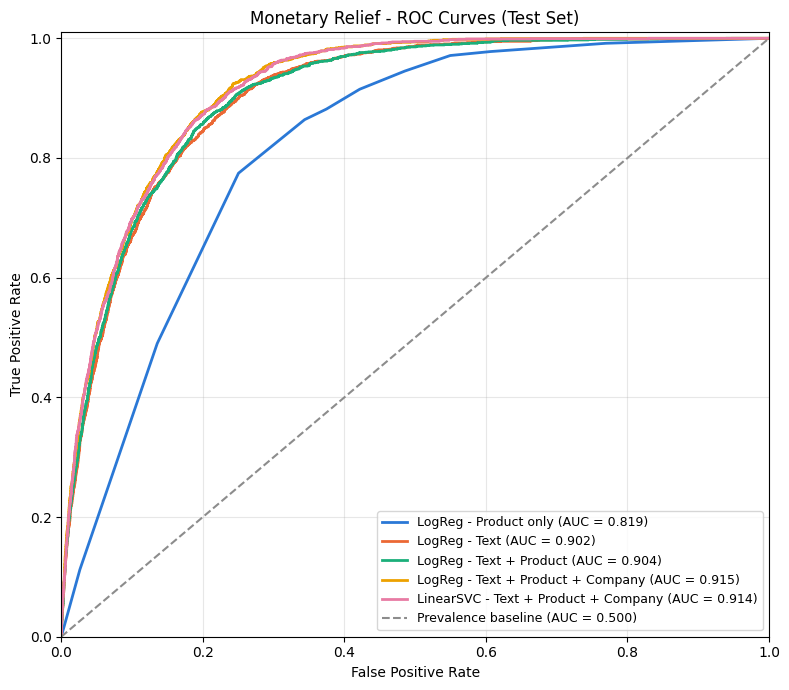

In [19]:
fig, ax = plt.subplots(figsize=(8, 7))

for key in VARIANT_ORDER:
    fpr, tpr, _ = roc_curve(y_test, test_scores[key])
    ax.plot(
        fpr,
        tpr,
        lw=2,
        color=VARIANT_COLORS[key],
        label=f"{results[key]['display_name']} (AUC = {results[key]['test_roc_auc']:.3f})",
    )

ax.plot(
    [0, 1],
    [0, 1],
    ls="--",
    lw=1.5,
    color=BASELINE_COLOR,
    label=f"Prevalence baseline (AUC = {results['prevalence']['test_roc_auc']:.3f})",
)

ax.set_title("Monetary Relief - ROC Curves (Test Set)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "relief_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

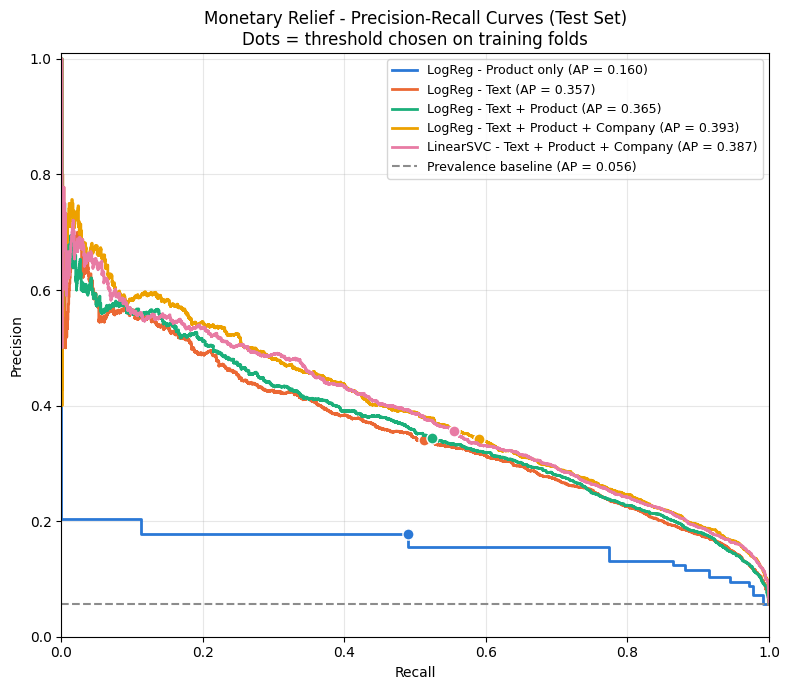

In [20]:
fig, ax = plt.subplots(figsize=(8, 7))

for key in VARIANT_ORDER:
    precision, recall, _ = precision_recall_curve(y_test, test_scores[key])
    ax.plot(
        recall,
        precision,
        lw=2,
        drawstyle="steps-post",
        color=VARIANT_COLORS[key],
        label=f"{results[key]['display_name']} (AP = {results[key]['test_pr_auc']:.3f})",
    )
    # Operating point chosen on train out-of-fold scores
    ax.plot(
        results[key]["test_recall"],
        results[key]["test_precision"],
        marker="o",
        markersize=8,
        markeredgecolor="white",
        color=VARIANT_COLORS[key],
        linestyle="none",
    )

ax.axhline(
    prevalence_test,
    ls="--",
    lw=1.5,
    color=BASELINE_COLOR,
    label=f"Prevalence baseline (AP = {prevalence_test:.3f})",
)

ax.set_title("Monetary Relief - Precision-Recall Curves (Test Set)\nDots = threshold chosen on training folds")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.grid(alpha=0.3)
ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "relief_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### Discrimination Within Each Product

Part of what the text model learns is simply *which product* a complaint is about, since relief rates differ by
product. Computing ROC-AUC and PR-AUC separately inside each product removes that between-product signal and shows
how well the model ranks complaints that share the same product.

In [21]:
within_rows = []

for product, idx in test_rel.groupby("Product").indices.items():
    y_product = y_test[idx]
    if y_product.min() == y_product.max():
        continue  # AUC is undefined without both classes

    row = {
        "Product": SHORT_LABELS[product],
        "test complaints": len(idx),
        "relief rate": y_product.mean(),
    }
    for key, label in [("text", "text"), ("text_product_company", "text+prod+company")]:
        row[f"ROC-AUC {label}"] = roc_auc_score(y_product, test_scores[key][idx])
        row[f"PR-AUC {label}"] = average_precision_score(y_product, test_scores[key][idx])
    within_rows.append(row)

within = pd.DataFrame(within_rows).set_index("Product").sort_values("relief rate", ascending=False)

weights = within["test complaints"]
for col in ["ROC-AUC text", "ROC-AUC text+prod+company"]:
    print(f"Size-weighted mean within-product {col}: {np.average(within[col], weights=weights):.4f}")

within.round(4)

Size-weighted mean within-product ROC-AUC text: 0.8337
Size-weighted mean within-product ROC-AUC text+prod+company: 0.8770


,test complaints,relief rate,ROC-AUC text,PR-AUC text,ROC-AUC text+prod+company,PR-AUC text+prod+company
Product,,,,,,
Prepaid Card,999,0.2032,0.8407,0.5297,0.8638,0.5488
Credit Card,3995,0.1712,0.7813,0.4058,0.7945,0.4398
Checking/Savings,3993,0.1290,0.7772,0.3487,0.8036,0.3948
Money Transfer,2992,0.0541,0.8605,0.2075,0.8766,0.2264
Payday/Personal Loan,1484,0.0404,0.8184,0.2199,0.8564,0.2274
Debt/Credit Mgmt,966,0.0331,0.8319,0.1678,0.8476,0.1861
Vehicle Loan,1988,0.0277,0.7821,0.1256,0.8323,0.1291
Mortgage,1991,0.0236,0.7783,0.0896,0.8172,0.0965
Student Loan,1741,0.0069,0.8604,0.0450,0.9307,0.0691


## 7. Terms Pushing Toward and Away From Monetary Relief

Coefficients of the text-only Logistic Regression. Positive weights raise the predicted probability of monetary
relief, negative weights lower it.

In [22]:
feature_names = tfidf.get_feature_names_out()
coefs = text_model.coef_[0]
order = np.argsort(coefs)

toward = order[::-1][:20]
away = order[:20]

top_terms = pd.DataFrame({
    "toward monetary relief": feature_names[toward],
    "weight (+)": coefs[toward].round(3),
    "away from monetary relief": feature_names[away],
    "weight (-)": coefs[away].round(3),
})
top_terms.index = range(1, 21)

top_terms

,toward monetary relief,weight (+),away from monetary relief,weight (-)
1,fee,6.231,cash app,-7.207
2,coinbase,5.995,cashapp,-5.909
3,citi,5.834,affirm,-5.370
4,bank america,5.548,debt,-5.233
5,fees,5.351,zelle,-4.910
6,america,5.265,credit report,-4.377
7,citibank,5.200,report,-4.337
8,amex,5.148,vanilla,-4.319
9,comenity,5.106,mortgage,-4.151
10,charges,5.056,netspend,-3.364


## 8. Save the Text-Only Model for the Demo

The demo only receives a narrative, so the text-only model (c) is saved as a single pipeline that takes
`clean_narrative` strings. The pipeline is reloaded to confirm that it reproduces the test probabilities.

In [23]:
relief_pipeline = Pipeline([
    ("tfidf", tfidf),
    ("clf", text_model),
])

model_path = MODEL_DIR / "relief_logreg.joblib"
joblib.dump(relief_pipeline, model_path)
print(f"Saved {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

loaded_pipeline = joblib.load(model_path)
reloaded_scores = loaded_pipeline.predict_proba(test_rel["clean_narrative"])[:, 1]

assert np.allclose(reloaded_scores, test_scores["text"])
print("Reloaded pipeline reproduces the text-only test probabilities.")
print(f"Decision threshold for the demo (F1-optimal on train OOF): {results['text']['threshold']:.4f}")

Saved ..\..\models\relief_logreg.joblib (5.2 MB)


Reloaded pipeline reproduces the text-only test probabilities.
Decision threshold for the demo (F1-optimal on train OOF): 0.7329


## 9. Discussion

**Label noise.** The company decides the outcome *after* the consumer has written the narrative, so the text can
only describe the situation, not the decision.
- **Template letters are not the main source of noise.** We expected identical letters sent to different companies
  to get different outcomes, but only 7 of 1,670 template groups have mixed outcomes. Template letters, including
  the January 2025 Cash App campaign, almost never receive monetary relief (0.2%).
- **The noise comes from company policy.** Similar complaints get very different outcomes depending on who receives
  them. Among checking and credit-card issuers in the training data, the rate ranges from 7.7% (Capital One) and
  8.2% (JPMorgan Chase) to 25.1% (Citibank), 31.6% (Bank of America) and 34.6% (American Express).

A text-only model cannot know these policies, which is one reason even the best variant only reaches PR-AUC ≈ 0.39.

**Company and product confounding.**
- **Product alone is a strong baseline.** It reaches ROC-AUC 0.819 and PR-AUC 0.160. The three credit bureaus
  (Experian 0.13%, Equifax 0.00%, TransUnion 0.01%) handle about 26,000 training complaints and almost never pay.
- **The text model is partly a company and product detector.** Many of its strongest positive terms are names
  (*citi, bank america, amex, coinbase, comenity, bofa, credit acceptance*), alongside money words (*fee, fees,
  charges, refund, dollaramount, late fee, claim*). The strongest negative terms are products and companies that
  rarely pay (*cash app, zelle, affirm, credit report, equifax, transunion, mortgage, nelnet, debt, collection*).
- **Within products, the text still ranks well.** Inside each product, the text model's ROC-AUC is 0.834 on
  average (weighted by test size), so the wording carries real information about which complaints get paid.
- **Explicit product features add little; company features add more.** Product on top of text adds only +0.008
  PR-AUC (0.357 → 0.365), because the text already reveals the product. Company adds another +0.028
  (0.365 → 0.393) and raises the within-product ROC-AUC to 0.877.
- **Caveat.** Company is a legitimate input, since it is known at routing time. But a model that leans on it
  predicts *company behavior*, not the merit of a complaint. It should be used to prioritize or route complaints,
  never to decide which consumers deserve attention.

**Why PR-AUC is the headline metric.**
- The text-only model has an impressive-looking ROC-AUC of 0.902. Yet at its operating point only 34% of flagged
  complaints actually receive monetary relief (precision 0.340, recall 0.513, 8.5% of test complaints flagged).
- ROC-AUC hides this because the false positive rate is computed over the very large negative class.
- PR-AUC measures precision directly, and its no-skill baseline equals the prevalence (0.056). The text model's
  PR-AUC of 0.357 is therefore an easy-to-read **6.3× lift** over random ranking.

**The thresholds transfer well, but the probabilities are not calibrated.**
- Thresholds chosen on the training folds hold up on test: the text model's out-of-fold F1 was 0.424 and its
  test F1 is 0.409.
- The chosen probability thresholds (0.72–0.78) are far above the 5.6% base rate, because
  `class_weight="balanced"` inflates the predicted probabilities.
- The demo should therefore compare the text model's score with its threshold (0.733, stored in
  `results/metrics/relief_text.json`) instead of showing the score as a literal probability.

## Monetary Relief Results Summary

The test set has 32,102 labeled complaints with a monetary relief prevalence of **0.056**. Precision, recall and F1
use the F1-optimal threshold chosen on training out-of-fold scores; the test set was not used to choose anything.

| Variant | Best C | CV PR-AUC | Test ROC-AUC | Test PR-AUC | Lift vs prevalence | Threshold | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|---|
| (a) Prevalence baseline | – | 0.058 | 0.500 | 0.056 | 1.0× | flag all | 0.056 | 1.000 | 0.107 |
| (b) Product only | 0.1 | 0.168 | 0.819 | 0.160 | 2.8× | 0.784 | 0.178 | 0.490 | 0.261 |
| (c) Text only | 0.5 | 0.375 | 0.902 | 0.357 | 6.3× | 0.733 | 0.340 | 0.513 | 0.409 |
| (d) Text + product | 0.5 | 0.387 | 0.904 | 0.365 | 6.5× | 0.743 | 0.345 | 0.524 | 0.416 |
| (e) Text + product + company | 0.5 | 0.414 | **0.915** | **0.393** | **7.0×** | 0.721 | 0.342 | **0.591** | 0.433 |
| (f) LinearSVC on (e) features | 0.02 | 0.408 | 0.914 | 0.387 | 6.9× | 0.446 (margin) | **0.356** | 0.555 | **0.434** |

- **Every model beats the prevalence baseline by a wide margin.** Product alone reaches 2.8× the baseline PR-AUC,
  and the narrative more than doubles that (6.3×).
- **The best model is Logistic Regression on text + product + company** (PR-AUC 0.393, ROC-AUC 0.915). LinearSVC on
  the same features is practically tied (PR-AUC 0.387, F1 0.434 vs 0.433). Its best C (0.02) sat at the low edge of
  its grid.
- **Product features add little once the text is used**, because the narrative already reveals the product.
  **Company** features add the most on top of text (+0.028 PR-AUC), because company policy drives the outcome
  (the relief rate ranges from about 0% at the credit bureaus to 35% at American Express).
- **Template letters are not a source of label noise.** They are almost uniformly "no relief", and only 7 of 1,670
  template groups have mixed outcomes.
- **The demo model** (`models/relief_logreg.joblib`, text-only Logistic Regression with C = 0.5) reloads and
  reproduces the notebook's test probabilities exactly. Its decision threshold is 0.733 (in
  `results/metrics/relief_text.json`). Its probabilities are inflated by class balancing, so they should be read
  as a ranking score.